# 5.3 - Choosing a learning algorithm, third version: learning what a portfolio earns

Two notebooks so far have asked whether the eight learning algorithms of Damon Lee's *Build Your Own AI Investor* can
pick S&P 1500 stocks when trained and chosen without hindsight:

* **5.1** used the book's set-up. No algorithm ranked companies better than chance.
* **5.2** repaired the learning task: percentile targets and features, settings for a weak signal, eight more
  features. The models then ranked companies clearly better than chance (rank ICs of +0.04 to +0.06, t-statistics up
  to 2.6), yet their portfolios earned no more than the market.

5.2 traced the gap to its target. A percentile teaches a model the **typical** (median) outcome, but a portfolio is
paid the **average** (mean) one. For volatile shares the two point in opposite directions: most lag, a few soar. The
models learned to avoid volatile shares - right about the typical one, wrong about the money.

This notebook changes three things, written down before any of its results were seen, and keeps everything else
from 5.2 (the 26 percentile features, the eight algorithms and their settings, the walk-forward training, the
portfolio):

1. **The target** becomes the year-ahead return in excess of the average member's, with each date's extremes clipped -
   a quantity whose average is what a portfolio earns.
2. **The yardstick** for choosing among the models becomes what the portfolio's entry group - the top 30 % by
   prediction - went on to earn. The rank IC is still shown, for comparison.
3. **A forecast that ranks nobody** (one value for every company) counts as no skill, and its portfolio holds the
   largest companies instead of cash - the two faults 5.2 found and reported without repairing.

## Why the mean and the median differ, and why it matters here

For a symmetric distribution - the bell curve - the mean and the median coincide. Stock returns over a year are
*positively skewed*: losses are capped at -100 %, gains are not, so a few very large gains pull the mean above the
median. The more volatile the share, the stronger the skew. In 5.2's data the most volatile fifth of S&P 1500 members
had a median year 7.4 points below the typical member's, but a mean 2.2 points *above* the average member's.

What each target teaches:

* A **percentile** target (5.2) gives the soaring few the same reward as any other winner: rank 1 for +30 % or
  +3,000 %. A least-squares fit to percentiles therefore predicts roughly a share's *median* rank - and volatile
  shares rank low.
* A **return** target (5.1) keeps the soaring few at full size, which is what a portfolio earns - but an +8,364 %
  year then outweighs a thousand ordinary companies, and the fit chases a handful of outliers.

The compromise is to keep returns but **clip** each date's extremes - an old remedy for outliers called
*winsorising*. On each decision date $t$, every member's year-ahead return $r_{i,t}$ is limited to that date's 1st and
99th percentiles $q_{1\%,t}$ and $q_{99\%,t}$, and the clipped average is taken off:
$$\tilde r_{i,t} = \min\big(\max(r_{i,t},\, q_{1\%,t}),\, q_{99\%,t}\big),\qquad
y_{i,t} = \tilde r_{i,t} - \frac{1}{N_t}\sum_{j} \tilde r_{j,t}.$$
With about 1,500 members, only the 15 most extreme at each end are clipped: a share that rose 80-fold counts as the
15th-best (still more than +100 %), and the other 98 % keep their returns as they were, so the soaring few still
lift the average of whatever group holds them. Taking off the date's average leaves nothing common to the date, as
in 5.2.

## The yardstick: what the entry group earned

5.1 and 5.2 chose among the models by the rank IC, the correlation between the order of predictions and the order of
returns. The IC is a fine measure of a ranking, but it is a rank measure: it shares the percentile's blindness to the
size of the soaring few, and it gives the bottom of the ranking as much weight as the top, while a long-only portfolio
only ever buys the top. This version chooses by the **top spread**: each month, the members a model ranks in its top
30 % (the portfolio's entry line), and the average target they went on to earn, less the average of all members:
$$S_t = \frac{1}{|T_t|}\sum_{i \in T_t} y_{i,t} \;-\; \frac{1}{N_t}\sum_{i} y_{i,t}.$$
It is in return units: a top spread of 0.02 means the top 30 % earned 2 percentage points more than the average
member over the following year. The members are weighted equally (the portfolio weights by market value) because a
few hundred equal weights measure the model's ranking with far less noise than a handful of giants would; the
portfolio's own result is measured in step 6. The rank IC is reported beside it.

A **flat forecast** - the same prediction for every member, which the elastic net gave on 38 month-ends in 5.2 when
cross-validation found nothing worth fitting - selects nobody and has no correlation. Here its top spread and its IC
that month are 0 (no skill), not missing, so the comparison between candidates is never stalled; and its portfolio
holds the largest 30 % of companies by market value, weighted by market value - most of the index's value - instead
of cash.

In [1]:
import warnings
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import ml
from equity_research.research import model_choice as mc
from equity_research.research import model_choice_v2 as v2
from equity_research.research import model_choice_v3 as v3
from equity_research.research.backtest import decile_returns
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.indices import calendar_years, vendor_returns
from equity_research.research.registry import trial_count
from equity_research.research.runs import score_metrics
from equity_research.research.strategy import TRAIN_FROM, StrategyConfig, deflated_active

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
charts.style()
# eps and sales growth have no values before 2008, so the first training windows lack them; the imputer drops such a
# column for that fit (and says so for every fit) - expected, not a fault
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
LABELS = {name: c.label for name, c in v3.CANDIDATES.items()} | {mc.FALLBACK: "Ensemble of all eight"}

## Step 1 - the protocol, fixed before any result

Written into every registered run's configuration (`model_choice_v3.PROTOCOL`). The candidates are 5.2's, setting for
setting (see 5.2 for what each setting does).

In [2]:
display(pd.Series({k: v for k, v in v3.PROTOCOL.items() if k != "candidates"}, name="rule").to_frame())

,rule
version,3
features,"ml.BOOK_CLIPS + ['momentum_12_1', 'return_1m',..."
target,year-ahead total return clipped to each date's...
training,"walk-forward, refitted each January, quarter e..."
criterion,mean monthly target of the top 30% of members ...
choice,each January the highest mean criterion so far...
flat,a date on which a score is one value for every...
distress,Altman Z'' <= 2.0 ranks last


## Step 2 - the data, the new target, the predictions

The S&P 1500, point-in-time, 2006 (training) to 2024; the 26 percentile features of 5.2.

In [3]:
cache = ResearchCache()
START, END = "2010-01-01", "2024-12-31"
data = load_universe_data(cache, "SP1500", TRAIN_FROM, END)
features = v2.ranked_features(data)
returns = ml.forward_returns(data.returns, data.rebalances)  # what each year paid
target = v3.trimmed_excess(returns, data.members)  # what the models learn, and what the yardstick measures
percentile = v2.ranked_target(returns, data.members)  # 5.2's target, for comparison
known = returns.where(data.members.reindex(index=returns.index, columns=returns.columns, fill_value=False))
raw, clipped = known.to_numpy(), target.to_numpy()
raw, clipped = raw[np.isfinite(raw)], clipped[np.isfinite(clipped)]
display(
    pd.DataFrame(
        {
            "common to the date": [
                v2.date_share(returns, data.members),
                v2.date_share(percentile, data.members),
                v2.date_share(target, data.members),
            ],
            "1st percentile": [np.percentile(raw, 1), 0.0, np.percentile(clipped, 1)],
            "99th percentile": [np.percentile(raw, 99), 1.0, np.percentile(clipped, 99)],
            "largest": [raw.max(), 1.0, clipped.max()],
        },
        index=["raw year-ahead return (5.1)", "percentile (5.2)", "clipped excess return (5.3)"],
    ).style.format(
        {
            "common to the date": "{:.0%}",
            "1st percentile": "{:+.2f}",
            "99th percentile": "{:+.2f}",
            "largest": "{:+,.2f}",
        }
    )
)

left out 887 facts of 2 companies in ['GBP']


,common to the date,1st percentile,99th percentile,largest
raw year-ahead return (5.1),18%,-0.77,+1.53,+83.64
percentile (5.2),0%,+0.00,+1.00,+1.00
clipped excess return (5.3),0%,-0.75,+1.04,+4.58


What each target says about volatile shares - by quintile of a year's volatility (1 calmest, 5 most volatile), over
all members and decision dates 2006-2023. The percentile's mean falls with volatility; the clipped excess return's
mean rises, because it keeps the soaring few.

In [4]:
volatility = v3.feature_panel(features, "volatility_1y")
by_vol = pd.concat(
    {
        "percentile (5.2)": v3.quintile_outcomes(volatility, percentile, data.members),
        "clipped excess return (5.3)": v3.quintile_outcomes(volatility, target, data.members),
    },
    axis=1,
)
display(by_vol.style.format("{:+.3f}"))

Each candidate's walk-forward predictions, refitted each January 2009-2024 on the quarter-ends whose year had ended
(stored, so a rerun reads them back).

In [5]:
predictions = mc.candidate_predictions(
    features,
    target,
    data.members,
    data.rebalances,
    candidates=v3.CANDIDATES,
    progress=lambda name, seconds, stored: print(
        f"{name:18s} {'read back' if stored else 'fitted'} in {seconds:,.0f} s"
    ),
)
flat_months = pd.Series({LABELS[n]: int(v3.flat(p, data.members).sum()) for n, p in predictions.items()})
print(
    "Month-ends on which a model gave every member the same prediction:",
    flat_months[flat_months > 0].to_dict() or "none",
)

linear             fitted in 4 s


elastic_net        fitted in 19 s


knn                fitted in 61 s


svr                fitted in 187 s


decision_tree      fitted in 10 s


random_forest      fitted in 174 s


extra_trees        fitted in 36 s


gradient_boosting  fitted in 16 s


Month-ends on which a model gave every member the same prediction: {'Elastic net': 192}


What each model follows: the average rank correlation, across companies, between its predictions and six features
(5.2's models leaned hard against volatility: -0.13 to -0.85).

In [6]:
lean_on = ["volatility_1y", "size", "RoE", "momentum_12_1", "share_change", "P/E"]
leaning = v3.leanings(predictions, {f: v3.feature_panel(features, f) for f in lean_on}).rename(index=LABELS)
display(leaning.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1, axis=None))

,volatility_1y,size,RoE,momentum_12_1,share_change,P/E
Linear regression,+0.12,-0.15,+0.10,-0.36,-0.19,-0.12
Elastic net,+nan,+nan,+nan,+nan,+nan,+nan
k-nearest neighbours,+0.06,-0.06,+0.13,-0.18,-0.17,-0.12
Support-vector regression,-0.09,+0.04,+0.10,-0.10,-0.09,+0.01
Decision tree,+0.03,-0.02,+0.09,-0.19,-0.14,-0.06
Random forest,+0.09,-0.07,+0.17,-0.31,-0.20,-0.11
Extra trees,+0.12,-0.10,+0.17,-0.37,-0.23,-0.18
Gradient-boosted trees,+0.11,-0.10,+0.10,-0.32,-0.14,-0.11


## Step 3 - what each model's top 30 % earned, out of sample

The top spread each month from January 2009 to December 2023 (the last month whose year has ended), with its
Newey-West t-statistic (neighbouring months share eleven of their twelve months of returns), and the rank IC beside
it.

,top spread,t,months positive,rank IC,IC t
Decision tree,+1.26%,+0.8,44%,+0.024,+1.7
Elastic net,+0.00%,+nan,0%,+0.000,+nan
Gradient-boosted trees,-0.05%,-0.1,49%,+0.013,+0.9
Support-vector regression,-0.53%,-1.3,47%,+0.002,+0.2
Random forest,-0.71%,-0.9,42%,+0.008,+0.5
k-nearest neighbours,-0.96%,-1.5,37%,-0.000,-0.0
Linear regression,-1.15%,-1.4,39%,-0.018,-1.3
Extra trees,-1.41%,-1.6,42%,-0.007,-0.4


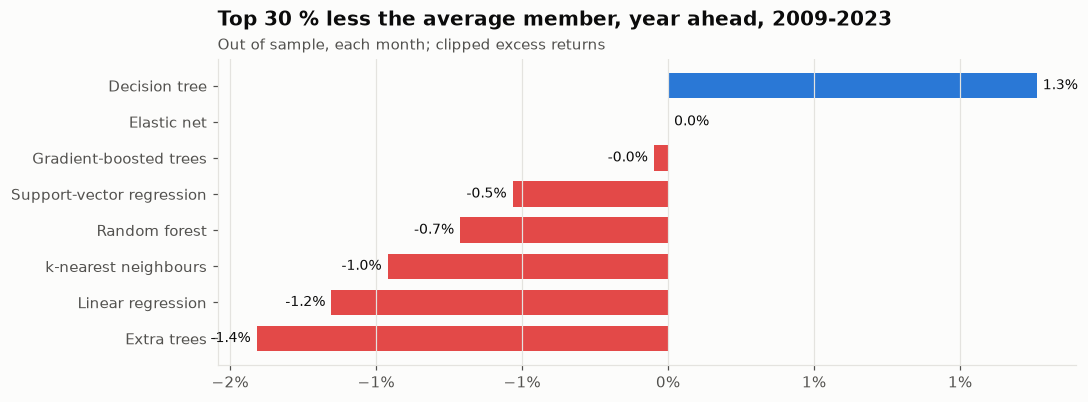

In [7]:
spreads = v3.top_spreads(predictions, target, data.members)
ic = v3.information_coefficients(predictions, returns, data.members)
s_sum, i_sum = mc.ic_summary(spreads), mc.ic_summary(ic)
summary = pd.DataFrame(
    {
        "top spread": s_sum["mean_ic"],
        "t": s_sum["t_nw"],
        "months positive": s_sum["positive"],
        "rank IC": i_sum["mean_ic"],
        "IC t": i_sum["t_nw"],
    }
).rename(index=LABELS)
summary = summary.sort_values("top spread", ascending=False)
display(
    summary.style.format(
        {"top spread": "{:+.2%}", "t": "{:+.1f}", "months positive": "{:.0%}", "rank IC": "{:+.3f}", "IC t": "{:+.1f}"}
    )
)
fig = charts.ranked_bars(
    summary["top spread"],
    "Top 30 % less the average member, year ahead, 2009-2023",
    subtitle="Out of sample, each month; clipped excess returns",
    percent=True,
)

In [8]:
yearly = spreads.groupby(spreads.index.year).mean().rename(columns=LABELS)
print("Mean top spread by the year of the decision date")
display(
    yearly.dropna(how="all")
    .style.format("{:+.1%}", na_rep="")
    .background_gradient(cmap="RdYlGn", vmin=-0.08, vmax=0.08, axis=None)
)

Mean top spread by the year of the decision date


,Linear regression,Elastic net,k-nearest neighbours,Support-vector regression,Decision tree,Random forest,Extra trees,Gradient-boosted trees
2009,-10.5%,+0.0%,-9.2%,-5.5%,-5.7%,-8.0%,-10.7%,-5.8%
2010,+0.2%,+0.0%,+0.3%,-0.7%,+0.4%,+0.7%,+0.2%,+0.3%
2011,-2.2%,+0.0%,-1.6%,-1.9%,-1.9%,-2.2%,-2.3%,-2.1%
2012,+0.4%,+0.0%,-0.8%,-1.4%,+2.6%,+0.1%,+0.4%,-0.2%
2013,+0.9%,+0.0%,+0.6%,+0.7%,-1.0%,+1.5%,+1.5%,+1.5%
2014,-1.3%,+0.0%,-2.2%,-0.1%,-1.8%,-2.2%,-3.9%,-1.1%
2015,-4.1%,+0.0%,-1.4%,+0.4%,-1.4%,-3.5%,-4.2%,-2.6%
2016,+0.5%,+0.0%,+0.6%,+0.3%,+0.7%,+1.3%,+1.4%,+0.5%
2017,+1.2%,+0.0%,+0.2%,+0.2%,-0.8%,-0.2%,-0.0%,+0.3%
2018,-1.5%,+0.0%,-1.7%,+0.1%,-5.1%,-1.8%,-2.5%,-0.7%


## Step 4 - the choice, made each January from what was known

Each January the candidate with the highest mean top spread over the months already known is used for the year (the
ensemble until 12 such months exist). Then: how the chosen model, the ensemble and the average of the eight did.

In [9]:
dates = data.rebalances[data.rebalances >= pd.Timestamp(START)]
table = mc.selection_table(spreads, dates)
shown = table.rename(columns=LABELS).assign(chosen=table["chosen"].map(LABELS))
display(shown.style.format({LABELS[n]: "{:+.2%}" for n in v3.CANDIDATES}, na_rep=""))
print(f"Hindsight winner over 2009-2023: {summary.index[0]}")
print("Years each model was chosen:", shown["chosen"].value_counts().to_dict())

,Linear regression,Elastic net,k-nearest neighbours,Support-vector regression,Decision tree,Random forest,Extra trees,Gradient-boosted trees,dates,chosen
year,,,,,,,,,,
2010,,,,,,,,,0,Ensemble of all eight
2011,-9.94%,+0.00%,-8.68%,-5.10%,-5.41%,-7.54%,-10.21%,-5.56%,13,Elastic net
2012,-5.14%,+0.00%,-4.42%,-3.14%,-2.66%,-3.62%,-5.26%,-2.77%,24,Elastic net
2013,-4.15%,+0.00%,-3.47%,-2.72%,-2.41%,-3.16%,-4.26%,-2.54%,36,Elastic net
2014,-3.00%,+0.00%,-2.80%,-2.40%,-1.14%,-2.35%,-3.11%,-1.94%,48,Elastic net
2015,-2.22%,+0.00%,-2.12%,-1.78%,-1.12%,-1.58%,-2.18%,-1.25%,60,Elastic net
2016,-2.06%,+0.00%,-2.13%,-1.50%,-1.24%,-1.68%,-2.48%,-1.22%,72,Elastic net
2017,-2.22%,+0.00%,-1.91%,-1.23%,-1.17%,-1.81%,-2.57%,-1.31%,85,Elastic net
2018,-2.01%,+0.00%,-1.70%,-1.04%,-1.01%,-1.53%,-2.21%,-1.19%,96,Elastic net


Hindsight winner over 2009-2023: Decision tree
Years each model was chosen: {'Elastic net': 11, 'Decision tree': 3, 'Ensemble of all eight': 1}


In [10]:
pooled = mc.ensemble(predictions, data.members)
chosen = mc.chosen_score(predictions, table["chosen"], data.members)
combined = {"walk-forward choice": chosen, "ensemble": pooled}
extra = pd.DataFrame({n: v3.top_spread(p, target, data.members) for n, p in combined.items()})
extra_ic = v3.information_coefficients(combined, returns, data.members)
display(
    pd.DataFrame(
        {
            "top spread 2010-2023": extra.loc[START:].mean(),
            "t": [mc.newey_west_t(extra.loc[START:][c]) for c in extra],
            "rank IC": extra_ic.loc[START:].mean(),
            "IC t": [mc.newey_west_t(extra_ic.loc[START:][c]) for c in extra_ic],
        }
    ).style.format({"top spread 2010-2023": "{:+.2%}", "t": "{:+.1f}", "rank IC": "{:+.3f}", "IC t": "{:+.1f}"})
)

,top spread 2010-2023,t,rank IC,IC t
walk-forward choice,+0.54%,+1.2,+0.017,+1.9
ensemble,+0.07%,+0.1,+0.011,+0.7


## Step 5 - deciles: next month's returns

Each month every score sorts the members into ten groups; each group's equal-weighted return over the next month in
excess of the average member, a year, from 2010 (before costs; Altman's distress zone ranks last).

In [11]:
scores = {name: p for name, p in predictions.items()} | {"walk-forward choice": chosen, mc.FALLBACK: pooled}
on_rebalance = data.members.reindex(data.rebalances)
scores = {
    name: ml.distress_last(v3.flat_to_index(s, on_rebalance, data.market_cap), data.ratios)
    for name, s in scores.items()
}
after = data.rebalances >= pd.Timestamp(START)
deciles = {LABELS.get(n, n): decile_returns(s.loc[after], data.returns, data.members) for n, s in scores.items()}
excess = pd.DataFrame({n: d["excess"] for n, d in deciles.items()}).T
excess["top t"] = [d.loc[10, "t"] for d in deciles.values()]
display(excess.style.format("{:+.1%}").format("{:+.1f}", subset=["top t"]))

decile,1,2,3,4,5,6,7,8,9,10,top t
Linear regression,-0.7%,+0.2%,+1.3%,+0.9%,+0.4%,-0.7%,+1.4%,-0.2%,-1.0%,-1.7%,-0.9
Elastic net,+0.9%,+1.3%,+0.3%,+0.4%,-0.6%,-0.5%,-1.0%,-0.8%,+0.2%,-0.2%,-0.1
k-nearest neighbours,+0.2%,-0.6%,-0.4%,+0.1%,+0.6%,+0.8%,-0.2%,+1.3%,-0.5%,-1.4%,-0.7
Support-vector regression,+0.5%,-1.5%,-0.4%,+0.9%,-1.1%,-0.1%,-0.1%,+0.8%,+0.7%,+0.3%,+0.3
Decision tree,+0.3%,+0.5%,-3.5%,+1.1%,-1.7%,-4.1%,+2.2%,+0.8%,+1.8%,+0.6%,+0.3
Random forest,-1.2%,+0.1%,-0.1%,-0.1%,+1.3%,+0.5%,+0.9%,+0.7%,+0.4%,-2.5%,-1.2
Extra trees,-1.1%,-0.4%,+1.2%,+0.7%,+0.8%,+0.2%,+1.3%,+1.0%,-0.6%,-3.0%,-1.2
Gradient-boosted trees,-1.9%,-0.8%,-1.2%,+1.0%,+0.5%,+0.8%,+0.1%,+1.2%,+0.6%,-0.4%,-0.2
walk-forward choice,+0.7%,+1.2%,+0.5%,+0.2%,-1.2%,-1.2%,-0.3%,-0.8%,-0.1%,+0.2%,+0.1
Ensemble of all eight,-0.9%,-1.3%,+0.5%,+1.0%,+0.1%,-0.0%,+0.5%,+1.0%,-0.5%,-0.4%,-0.2


## Step 6 - the portfolios, every one registered

5.1's portfolio for every score, registered in the family `ml_model_choice_v3_lo`. The deflated active Sharpe ratio is
shown counting this family's ten trials and counting all three versions' thirty - three tries at one question.

In [12]:
# the registry is the shared database: connected here, just before the runs, because a serverless database
# pauses when idle and is woken by the first connection
engine = get_engine()
base = StrategyConfig(
    family=v3.FAMILY,
    universe="SP1500",
    start=START,
    end=END,
    enter=0.30,
    exit_=0.40,
    long_only=True,
    beta_neutral=False,
    weighting="market_cap",
)
runs = {}
for name, score in scores.items():
    config = replace(base, factors=((f"ml:{name}", 1.0),))
    runs[LABELS.get(name, name)] = mc.run_score(data, config, score, protocol=v3.PROTOCOL, engine=engine)
# each run's own record is deflated by the trials registered before it; once all ten are in, every run is deflated
# by the family's full count - and by all three versions'
own = trial_count(engine, v3.FAMILY)
every = sum(trial_count(engine, family) for family in (mc.FAMILY, v2.FAMILY, v3.FAMILY))
sptm = vendor_returns(cache, "SPTM", total=True)
metrics = pd.DataFrame({name: r.metrics for name, r in runs.items()}).T
for label, trials in (("deflated, this version", own), ("deflated, all versions", every)):
    metrics[label] = [
        deflated_active(r.backtest.net, data.benchmark, float(r.metrics["information_ratio"]), trials)
        for r in runs.values()
    ]
COLUMNS = {
    "cagr": "{:.1%}",
    "vol": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated, this version": "{:.0%}",
    "deflated, all versions": "{:.0%}",
    "turnover": "{:.1f}",
}
display(metrics[list(COLUMNS)].sort_values("information_ratio", ascending=False).style.format(COLUMNS))
print("Registered as research runs", {name: r.run_id for name, r in runs.items()})
print("Trials in this family:", own, "| in all three versions:", every)

,cagr,vol,sharpe,max_drawdown,active_return,tracking_error,information_ratio,"deflated, this version","deflated, all versions",turnover
Support-vector regression,15.3%,18.1%,0.88,-34%,+1.1%,3.3%,+0.36,43%,25%,4.9
Elastic net,14.1%,17.2%,0.85,-34%,+0.1%,1.4%,+0.04,8%,3%,0.2
Ensemble of all eight,13.9%,18.1%,0.81,-32%,-0.0%,4.9%,+0.03,7%,2%,3.5
Extra trees,13.8%,18.2%,0.80,-32%,-0.2%,4.9%,-0.00,6%,2%,3.0
Gradient-boosted trees,13.5%,18.7%,0.77,-34%,-0.5%,4.9%,-0.04,4%,1%,4.5
Linear regression,13.2%,18.5%,0.76,-33%,-0.7%,5.0%,-0.10,3%,1%,3.9
k-nearest neighbours,13.4%,17.8%,0.80,-32%,-0.5%,4.0%,-0.12,2%,1%,3.7
Random forest,12.1%,18.0%,0.73,-32%,-1.6%,4.8%,-0.32,0%,0%,3.3
Decision tree,11.4%,17.6%,0.70,-32%,-2.3%,5.1%,-0.44,0%,0%,2.8
walk-forward choice,11.8%,17.6%,0.72,-34%,-1.9%,4.1%,-0.47,0%,0%,1.2


Registered as research runs {'Linear regression': 160, 'Elastic net': 161, 'k-nearest neighbours': 162, 'Support-vector regression': 163, 'Decision tree': 164, 'Random forest': 165, 'Extra trees': 166, 'Gradient-boosted trees': 167, 'walk-forward choice': 168, 'Ensemble of all eight': 169}
Trials in this family: 10 | in all three versions: 30


### The three versions, model by model

The same portfolio and the same algorithm in each version (the newest registered run of each score in each family).

In [13]:
versions = {
    "5.1": score_metrics(engine, mc.FAMILY).rename(index=LABELS),
    "5.2": score_metrics(engine, v2.FAMILY).rename(index=LABELS),
    "5.3": metrics,
}
pairs = {"return a year": "cagr", "information ratio": "information_ratio"}
side = pd.concat(
    {label: pd.DataFrame({v: m[key] for v, m in versions.items()}) for label, key in pairs.items()}, axis=1
)
side = side.loc[metrics.sort_values("information_ratio", ascending=False).index]
display(side.style.format("{:.1%}", subset=["return a year"]).format("{:+.2f}", subset=["information ratio"]))

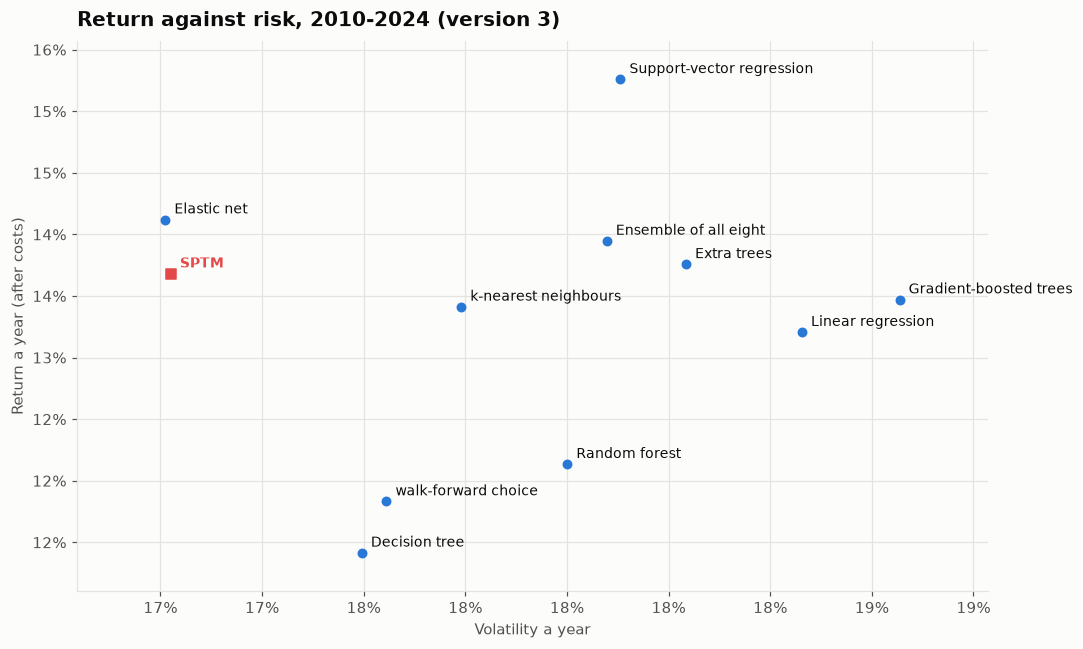

In [14]:
spread = metrics[["vol", "cagr"]].astype(float).rename(columns={"vol": "x", "cagr": "y"})
spread.loc["SPTM"] = [
    float(sptm.loc[START:END].std() * np.sqrt(252)),
    float((1 + sptm.loc[START:END]).prod() ** (252 / len(sptm.loc[START:END])) - 1),
]
fig = charts.labeled_scatter(
    spread,
    "Return against risk, 2010-2024 (version 3)",
    xlabel="Volatility a year",
    ylabel="Return a year (after costs)",
    highlight="SPTM",
)

Each year: the portfolio's return minus SPTM's


trade_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
walk-forward choice,-5.7%,-0.2%,-0.0%,-1.5%,-1.2%,+1.6%,-0.8%,+1.2%,+0.7%,-0.0%,+1.0%,-0.7%,-3.9%,-13.2%,-10.0%
Ensemble of all eight,-5.7%,+2.0%,+0.6%,-2.8%,-0.3%,-4.5%,+3.5%,+0.9%,-3.0%,+5.6%,+10.3%,+0.3%,-11.8%,+18.2%,-3.4%
Gradient-boosted trees,-5.6%,+0.1%,+1.3%,+0.6%,-1.2%,-5.1%,+4.5%,+0.7%,-0.1%,-1.0%,+4.9%,+4.6%,-11.2%,+14.3%,-6.1%


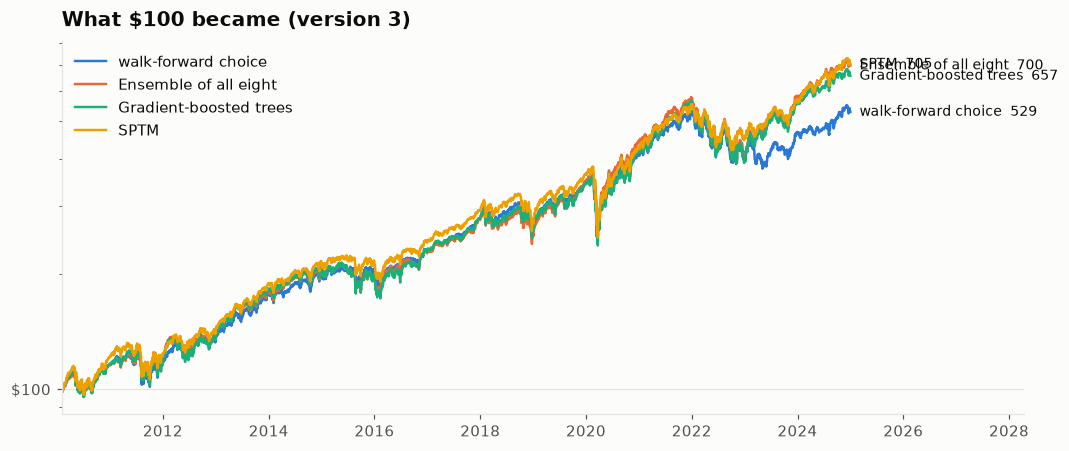

In [15]:
shown_runs = {
    k: runs[k].backtest.net for k in ("walk-forward choice", "Ensemble of all eight", "Gradient-boosted trees")
}
fig = charts.growth(shown_runs | {"SPTM": sptm}, "What $100 became (version 3)")
ahead = pd.DataFrame(
    {
        name: calendar_years({name: r, "SPTM": sptm}).pipe(lambda t, n=name: t[n] - t["SPTM"])
        for name, r in shown_runs.items()
    }
)
print("Each year: the portfolio's return minus SPTM's")
display(ahead.T.style.format("{:+.1%}", na_rep=""))

## Findings

**In short: a target that keeps the size of returns let two market rebounds dictate what the models learned, and the
ranking skill of 5.2 disappeared.** The models' top 30 % earned less than the average member. The rule for choosing
then did what it was built to do when nothing works: it chose the model that abstains, and held the largest
companies. After three pre-registered attempts and thirty trials, no learned score from these features beats the
market.

**1. The new target kept less of the average than intended (step 2).** Clipping removed the absurd: the largest
value fell from a return of +8,364 % to 458 points over the average member (on the most extreme date the 99th
percentile is itself that high). But across
volatility quintiles the clipped target's mean rises only from -1.1 points (the calmest fifth) to +1.0 (the fourth)
and falls back to 0.0 for the most volatile fifth. Before clipping, that fifth's average was +2.2 points. So the
soaring few that make volatile shares pay on average are largely the top 1 % - the very companies the clipping caps.
The medians still fall steeply, to -6.9 points for the most volatile fifth.

**2. The elastic net never fitted anything (step 2).** On all 192 month-ends its cross-validation found no penalty
small enough to let any feature in, and it predicted the same value for every company. Inside every training window,
on the training years alone, the most honest internal test available found no linear relation between these 26
features and next year's excess return.

**3. The other models learned to buy past losers.** Their predictions lean against 12-1 month momentum (rank
correlations -0.10 to -0.37). In 5.2 they had leaned against volatility instead (-0.13 to -0.85); here volatility
barely registers (-0.09 to +0.12). The reason lies in what least squares weighs. A diagnosis after the run (same
data, nothing refitted) measured each decision year's share of the squared target:

* The decision dates of 2008-2009 carry 70 % of the squared target in the training window used for 2011, 46 % for
  2015, 31 % for 2020 and still 20 % for 2024. In those two years past losers beat past winners: the rank
  correlation between momentum and the target was -0.10 and -0.16, as the shares hit hardest in the crash rebounded
  hardest.
* The dates of 2020, which looked into the rally of 2021, carry another 19 % of the whole, with momentum at -0.26.

A model fitted on squared errors mostly fits those two rebounds and carries their lesson - buy what fell - into
every other year, where it does not hold.

**4. No model's top 30 % earned more than the average member (step 3).** The mean top spreads over 2009-2023 run from
-1.41 % a year (extra trees, t -1.6) to +1.26 % (the decision tree, t 0.8). Six of the eight are negative, and the
elastic net is 0 by the flat-forecast rule. The decision tree's positive mean comes from two decision years, 2019
(+10.5 %) and 2020 (+20.5 %); in 8 of the other 13 years it was negative. The rank ICs are back near zero (-0.018
to +0.024, no t above 1.7). The top deciles of next month's returns run from -3.0 % to +0.6 % a year (step 5).

**5. The choice abstained, then switched at the worst moment (step 4).** Every model's running record was negative,
so the elastic net, scored 0 for a flat forecast, led every January from 2011 to 2021. In those years the portfolio
held the largest 30 % of companies by market value, and stayed within 1.6 points of SPTM each year. That is the rule
working: no evidence of skill, so no bet. In January 2022 the decision tree's running mean turned positive
(+1.35 %), on the strength of its two exceptional years, and the choice switched to it. The portfolio then fell 3.9
points behind SPTM in 2022, 13.2 in 2023 and 10.0 in 2024, ending at 11.8 % a year against SPTM's 13.7 %.

**6. The portfolios (step 6).** Returns range from 11.4 % (the decision tree) to 15.3 % (SVR) a year, with volatility
of 17.2 % to 18.7 %. The lower risk of 5.2's portfolios (16.2 % to 17.9 %) went with the low-volatility tilt. The
elastic net's portfolio is in effect the largest companies: 14.1 % a year, a tracking error of only 1.4 %,
information ratio +0.04.

SVR's portfolio again did best: 15.3 % a year, information ratio +0.36. It is the one result consistent across all
three versions (14.2 %, 15.2 %, 15.3 %), though its own ranking measures were weak each time. Its deflated active
Sharpe ratio is 43 % counting this version's ten trials and 25 % counting all three versions' thirty, far from 95 %.

| | 5.1: return / IR | 5.2: return / IR | 5.3: return / IR |
|---|---|---|---|
| walk-forward choice | 13.2 % / -0.15 | 13.3 % / -0.21 | 11.8 % / -0.47 |
| ensemble of all eight | 13.7 % / -0.01 | 13.8 % / -0.10 | 13.9 % / +0.03 |
| gradient-boosted trees | 13.7 % / -0.01 | 13.7 % / -0.11 | 13.5 % / -0.04 |
| SVR | 14.2 % / +0.08 | 15.2 % / +0.38 | 15.3 % / +0.36 |

**What the three versions show together.**

* **5.1** (the book's set-up): no ranking skill and no portfolio edge.
* **5.2** (percentile target): a real, statistically significant ranking of *typical* outcomes. It was a tilt
  towards calm, large, profitable companies that lowered risk without raising return - an effect a plain
  low-volatility or quality factor (notebooks 3.1-3.3) delivers more simply.
* **5.3** (a target that keeps return sizes): the fit was dominated by two crisis rebounds and lost the ranking
  altogether.

The robust target optimises the wrong quantity, and the right quantity is at the mercy of a few episodes. With a
year's horizon there are only about fifteen independent years in the data, and two of them decide what a
least-squares model learns.

**What not to do next** is a version 4 tuned on these results: every further variant raises the bar (the deflated
ratios already count thirty trials), and the ideas a fourth version would try are all chosen with hindsight. These
include a robust loss, volatility-scaled targets, and requiring t > 2 before leaving the index. The questions that
remain belong to the machine-learning plan's groundwork (docs/ML4T_PLAN.md, P0-P1):

* shorter label horizons, with many more independent observations;
* cross-validation that purges overlapping labels;
* features screened one by one before any model sees them.

The hold-out from 2025 stays closed.

The portfolios are research runs 160-169 in the family `ml_model_choice_v3_lo`. Their own records deflate each run
by the trials registered before it (1 to 10); the table in step 6 deflates them all by the family's ten and by all
three versions' thirty.


## Glossary

Terms defined in notebooks 5.1 and 5.2 are not repeated.

* **Mean / median** - the average, and the middle value once sorted; they differ when a distribution is skewed.
* **Skewness** - lopsidedness of a distribution; *positive* skew means a long tail of large values, as in stock
  returns, whose losses stop at -100 % while gains do not.
* **Excess return** - a return less a benchmark's; here less the average index member's on the same date.
* **Winsorising (clipping)** - replacing values beyond chosen percentiles with those percentiles, so extremes keep
  their sign and most of their size without dominating an average.
* **Top spread** - the average excess return of a model's top 30 % of members over the year after the prediction: what
  the portfolio's entry group earned beyond the average member.
* **Flat forecast** - a model's predicting the same value for every company: it ranks nobody.